- Aluno: Matheus Peixoto Ribeiro Vieira
- Matrícula: 22.1.4104

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Função de Rastrigin
def rastrigin(x, y):
    return 20 + x**2 - 10*np.cos(2*np.pi*x) + y**2 - 10*np.cos(2*np.pi*y)

def pso(w=0.7, c1=1.5, c2=1.5, n_particles=30, max_iter=40):
    # 3. Inicialização
    X = np.random.uniform(-5.12, 5.12, (n_particles, 2))
    V = np.random.uniform(-1, 1, (n_particles, 2))
    pbest = X.copy()
    pbest_obj = rastrigin(X[:, 0], X[:, 1])
    gbest = pbest[np.argmin(pbest_obj)]
    gbest_obj = np.min(pbest_obj)

    # 4. Preparação para os plots
    fig, axes = plt.subplots(1, 5, figsize=(25, 5), sharey=True)
    plot_idx = 0

    # Grid para o fundo do gráfico
    x_range = np.linspace(-5.12, 5.12, 100)
    y_range = np.linspace(-5.12, 5.12, 100)
    X_mesh, Y_mesh = np.meshgrid(x_range, y_range)
    Z_mesh = rastrigin(X_mesh, Y_mesh)

    # 5. Loop do PSO
    for i in range(max_iter+1):
        # Plota a cada 10 iterações
        if i % 10 == 0:
            ax = axes[plot_idx]
            ax.contour(X_mesh, Y_mesh, Z_mesh, 15, cmap='viridis', alpha=0.3)
            ax.scatter(X[:, 0], X[:, 1], color='red', s=20, edgecolors='black', label='Partículas')
            ax.scatter(gbest[0], gbest[1], color='gold', marker='*', s=150, edgecolors='black', label='Líder')
            ax.set_title(f"Iteração {i}\nMelhor: {gbest_obj:.2f}")
            ax.set_xlim(-5.12, 5.12)
            ax.set_ylim(-5.12, 5.12)
            plot_idx += 1

        # Atualização das Partículas
        r1, r2 = np.random.rand(n_particles, 2), np.random.rand(n_particles, 2)
        V = w*V + c1*r1*(pbest - X) + c2*r2*(gbest - X)
        X = X + V

        # Avaliação de Fitness
        obj = rastrigin(X[:, 0], X[:, 1])
        mask = obj < pbest_obj
        pbest[mask] = X[mask]
        pbest_obj[mask] = obj[mask]

        if np.min(pbest_obj) < gbest_obj:
            gbest = pbest[np.argmin(pbest_obj)]
            gbest_obj = np.min(pbest_obj)

    plt.tight_layout()
    plt.show()

    print(f"gbest: {gbest}")
    print(f"gbest obj: {gbest_obj}")

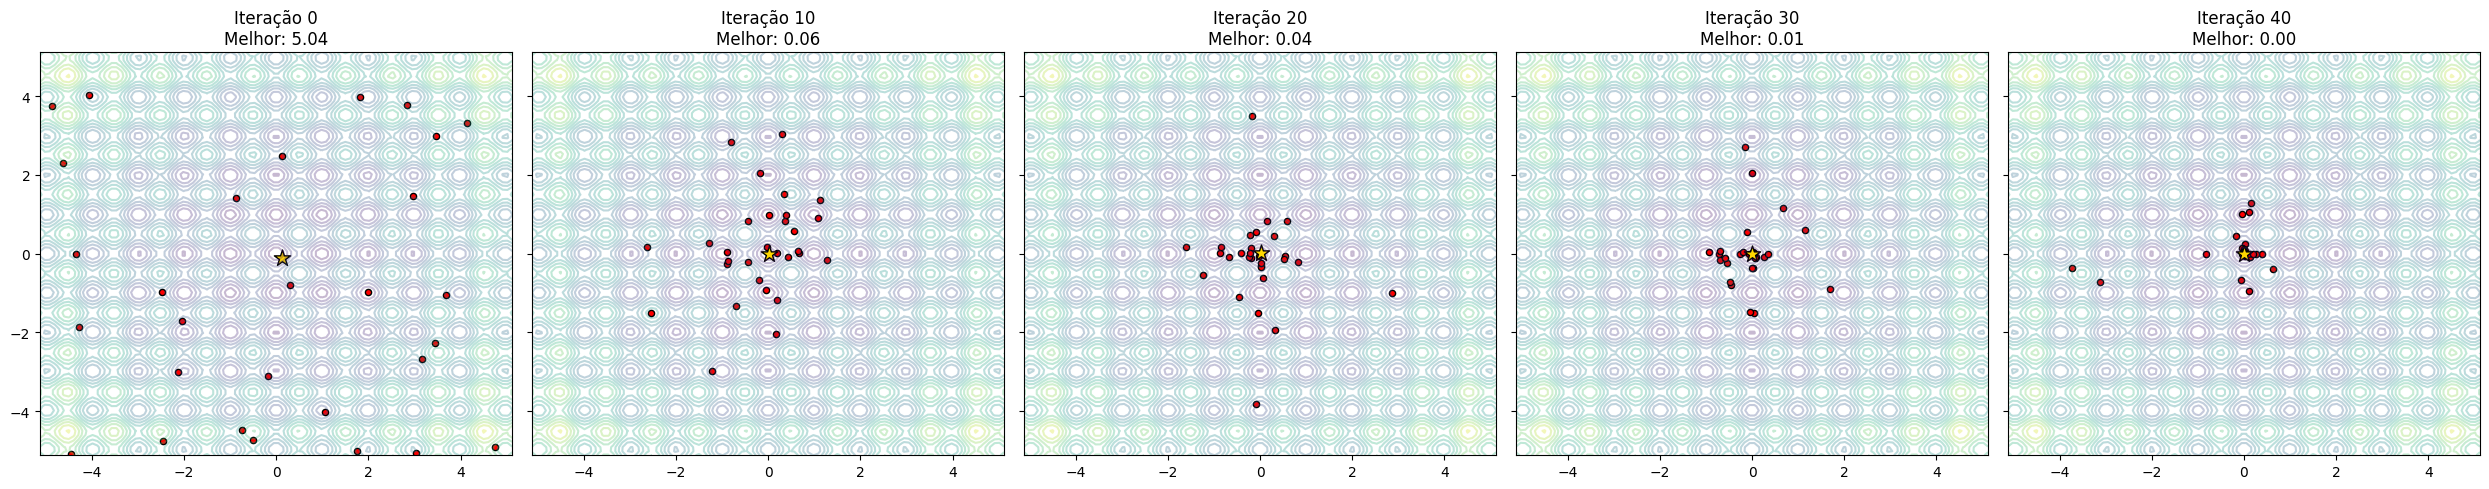

gbest: [0.00140325 0.00295793]
gbest obj: 0.002126407676703579


In [9]:
# A
pso(0.7, 1.5, 1.5)

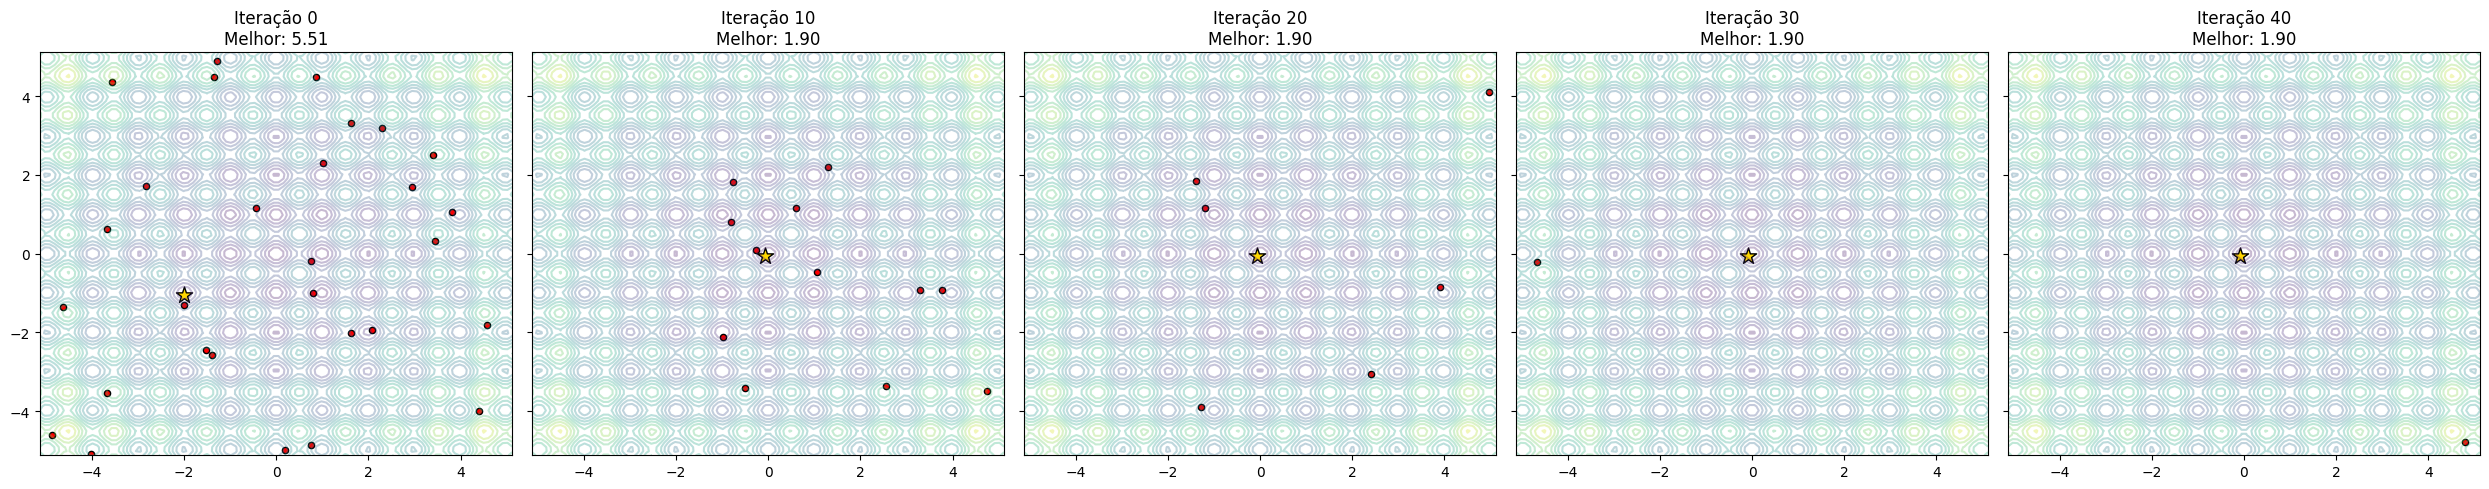

gbest: [-0.07684971 -0.06181587]
gbest obj: 1.8978660476112292


In [10]:
# B
pso(1.2, 0.5, 0.5)

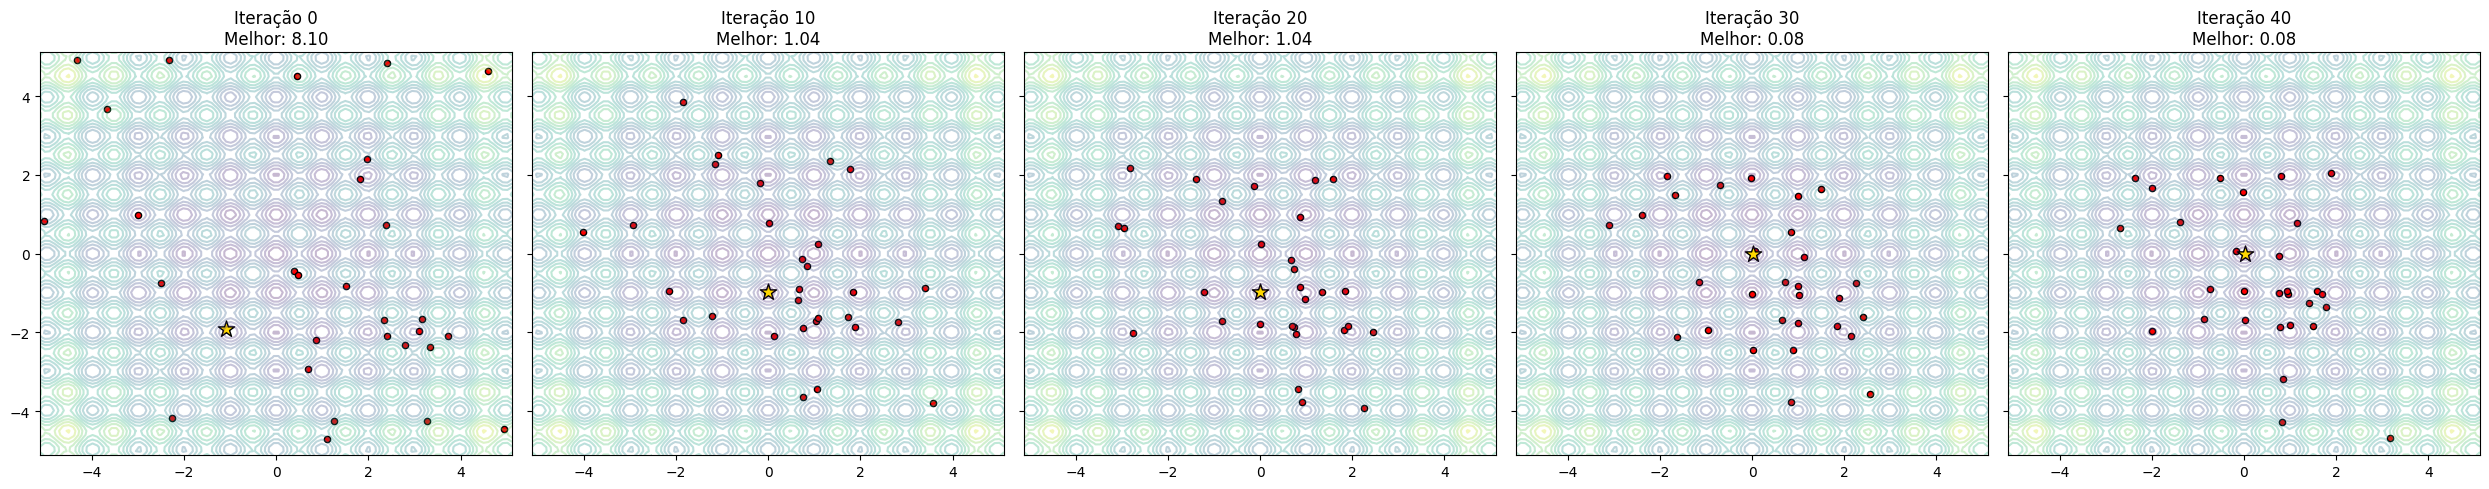

gbest: [0.01994852 0.00095992]
gbest obj: 0.07902884787802833


In [14]:
# C
pso(0.5, 2.5, 0.2)

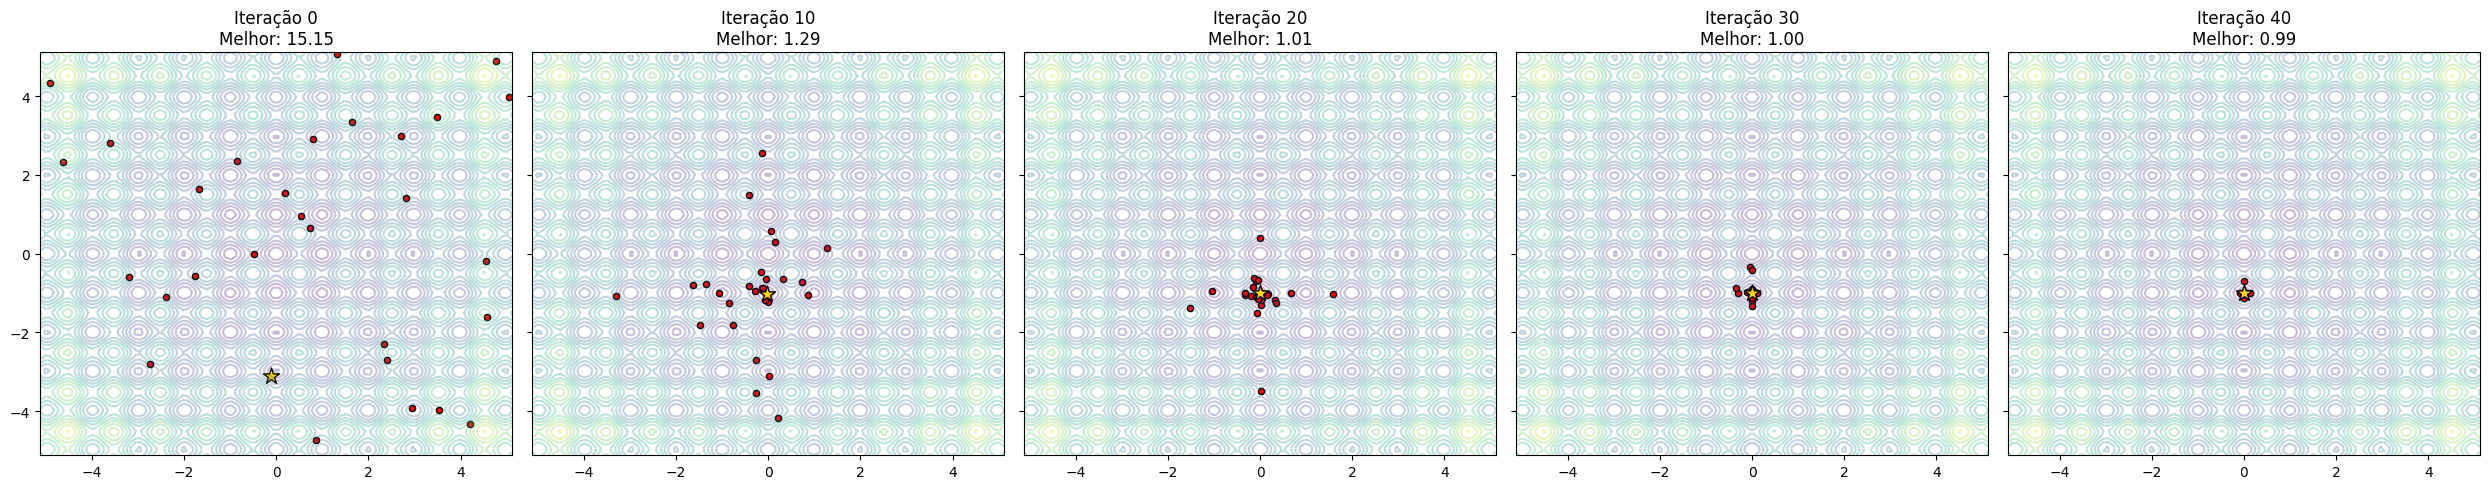

gbest: [ 2.40125099e-05 -9.94935534e-01]
gbest obj: 0.9949592773262115


In [12]:
# D
pso(0.5, 0.2, 2.5)

# Questões para discussão
## 1 - Qual configuração chegou mais erto do zero real (0,0)?
A configuração A, pois obteve um gbest [0.0014, 0.0030] e um gbest_obj = 0.0021, o menor entre todos

## 2 - O que aconteceu no Caso B?
A inércia estava muito alta e o c1 e c2 muito baixos. Isso fez com que as partículas oscilassem muito, pois têm uma alta velocidade e pouca força

## 3 - No Caso C, o enxame se espalhou ou se agrupou rapidamente?
As partículas permaneceram muito distribuídas, então não é possível falar que agrupou rapidamente, pois apresentou uma convergência extremamente devagar para a região do ótimo. Mas isso é explicado pelo c alto e c2 baixo, então as partículas procuram o seus ótimos locais.

## 4 - Se você tivesse um problema onde o tempo de processamento é muito curto, qual desses perfis você escolheria?
B e C são descartados por serem mais devagar. O D converge muito rapidamente, mas para um minimo local e não global, como pode ser visto pelo gbest_obj de quase 1. Assim, o A possui o melhor trade-off de tempo e qualidade de convergência, e por isso é o perfil que mais faz sentido quando se escolhe um tempo de processamento curto. Porque nada adianta ser rápido, mas errado.